# Exploratory Data Analysis on Online Retail Dataset (Dec 2010 - Dec 2011)

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

# Configure plot style and display settings 
plt.style.use('ggplot') 
sns.set_theme(style="whitegrid") 
%matplotlib inline

In [7]:
import os

path = r'C:\Users\unique\OneDrive\Desktop\EDA GUIDED DATASET\online_retail_II.csv'

print(os.path.isdir(path))
print(os.listdir(path))

True
['online_retail_II.csv']


In [8]:
df = pd.read_csv(
    r'C:\Users\unique\OneDrive\Desktop\EDA GUIDED DATASET\online_retail_II.csv\online_retail_II.csv',
    encoding='latin1'
)

In [ ]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


# DATA CLEANING


In [ ]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 66.2 MB


In [ ]:
df.describe().round()

,Quantity,Price,Customer ID
count,541910.0,541910.0,406830.0
mean,10.0,5.0,15288.0
std,218.0,97.0,1714.0
min,-80995.0,-11062.0,12346.0
25%,1.0,1.0,13953.0
50%,3.0,2.0,15152.0
75%,10.0,4.0,16791.0
max,80995.0,38970.0,18287.0


In [ ]:
# checking missing values
df.isnull().sum()/len(df)*100

Invoice         0.000000
StockCode       0.000000
Description     0.268310
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    24.926648
Country         0.000000
dtype: float64

In [ ]:
# checking duplicate values 
df.duplicated()
# top 20 duplicate rows
df[df.duplicated()].shape

(5268, 8)

In [ ]:
#removing duplicates
df.drop_duplicates()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


In [ ]:
df['Customer ID'].value_counts()

Customer ID
17841.0    7983
14911.0    5903
14096.0    5128
12748.0    4642
14606.0    2782
           ... 
18184.0       1
13256.0       1
13017.0       1
18174.0       1
15195.0       1
Name: count, Length: 4372, dtype: int64

# HANDLING MISSING VALUES 

In [ ]:
df.dropna(subset=['Customer ID'],inplace=True)
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


In [ ]:
df['Description'].isnull().sum()

np.int64(0)

# FIXING INCONSISTENT FORMATTING

In [ ]:
# Fixing formatting of StockCode column
df['StockCode'] = df['StockCode'].astype(str).str.strip().str.upper()
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


# HANDLING DUPLICATES VALUES

In [ ]:
# DUPLICATE VALUES
df[df.duplicated()].shape

(5225, 8)

In [ ]:
#REMOVING DUPLICATES
df.drop_duplicates(inplace=True)
df[df.duplicated()].shape

(0, 8)

# CORRECTING DATA TYPES

In [ ]:
df.dtypes

Invoice            str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
Price          float64
Customer ID    float64
Country            str
dtype: object

In [ ]:
# changing datatype of invoice and customer ID 
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Customer ID'] = df['Customer ID'].astype('Int64').astype(str)
df.info()

C:\Users\unique\AppData\Local\Temp\ipykernel_10772\3647223116.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


<class 'pandas.DataFrame'>
Index: 401605 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      401605 non-null  str           
 1   StockCode    401605 non-null  str           
 2   Description  401605 non-null  str           
 3   Quantity     401605 non-null  int64         
 4   InvoiceDate  401605 non-null  datetime64[us]
 5   Price        401605 non-null  float64       
 6   Customer ID  401605 non-null  str           
 7   Country      401605 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(5)
memory usage: 49.2 MB


In [ ]:
df.describe().round()

,Quantity,InvoiceDate,Price
count,401605.0,401605,401605.0
mean,12.0,2011-07-10 12:08:56.555570,3.0
min,-80995.0,2010-12-01 08:26:00,0.0
25%,2.0,2011-04-06 15:02:00,1.0
50%,5.0,2011-07-29 15:40:00,2.0
75%,12.0,2011-10-20 12:00:00,4.0
max,80995.0,2011-12-09 12:50:00,38970.0
std,250.0,NaN,70.0


# REMOVING OUTLIERS

In [ ]:
# 1. Filter out extreme price and quantity errors to create a clean DataFrame
# (Keeping prices between 0 and 5000, and absolute quantities under 10,000)

df_clean = df[(df['Price'] > 0) & (df['Price'] < 5000) &  (df['Quantity'] > 0) & (df['Quantity'] < 10000)]



In [ ]:
# 2. Check the updated summary statistics using describe() to verify the cleaning
df_clean.describe().round(2)

,Quantity,InvoiceDate,Price
count,392690.00,392690,392690.00
mean,12.72,2011-07-10 19:14:00.964119,3.11
min,1.00,2010-12-01 08:26:00,0.00
25%,2.00,2011-04-07 11:12:00,1.25
50%,6.00,2011-07-31 12:02:00,1.95
75%,12.00,2011-10-20 12:53:00,3.75
max,4800.00,2011-12-09 12:50:00,4161.06
std,43.08,NaN,18.06


# PERFORMING EDA

In [ ]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


#  UNIVARIATE ANALYSIS 

Quantity Column Analysis — Conclusion
1. The quantity distribution is highly positively skewed, with an original skewness of 29.87.
2. The mean quantity is 12.72, while the median is 6, indicating that a relatively small number of large-quantity transactions pull the mean upward.
3. The maximum quantity is 4,800, showing that some transactions contain substantially larger quantities than typical transactions.
4. Applying the log1p() transformation reduced the skewness from 29.87 to 0.82, making the distribution less right-skewed.
5. The log transformation compresses extreme values but does not remove them from the dataset.

**Final observation:** Most transactions involve relatively small quantities, while a smaller number of transactions involve much larger quantities.


In [ ]:
# CHECKING THE SKEWNESS
df_clean['Quantity'].skew()

np.float64(29.8740186443045)

In [ ]:
# CHECKING EXTREME VALUES 
df_clean['Quantity'].nlargest(10)

421632    4800
206121    4300
97432     3906
270885    3186
52711     3114
160546    3114
433788    3000
4945      2880
291249    2880
201149    2700
Name: Quantity, dtype: int64

In [ ]:
# COMPARING MEAN , MEDIAN , MIN, MAX
df_clean['Quantity'].agg(['mean', 'median', 'min' , 'max']).round(2)

mean        12.72
median       6.00
min          1.00
max       4800.00
Name: Quantity, dtype: float64

In [ ]:
# LOG TRANSFORMATION TO REDUCE SKEWNESS AND COMPRESS THE EXTREME VALUES
np.log1p(df_clean['Quantity']).skew().round(2)

np.float64(0.82)

In [ ]:
df_clean['Quantity_log']= np.log1p(df_clean['Quantity'])

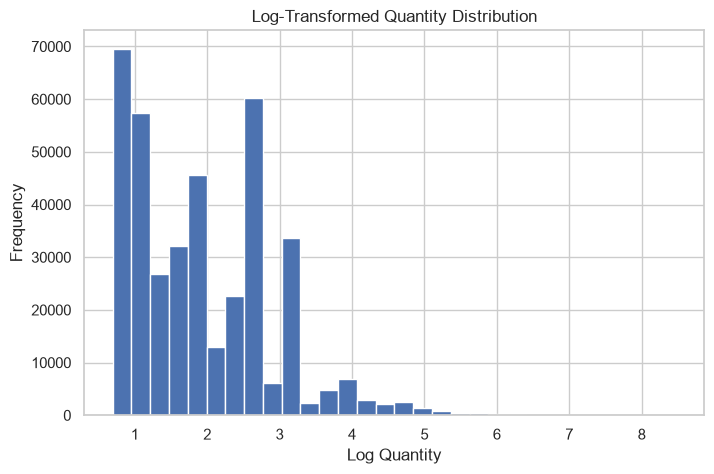

In [ ]:
# plotting histogram of the log-transformed quantity values to visualize the distribution.
df_clean['Quantity_log'].plot(kind='hist', bins=30 , figsize=(8,5))
plt.title('Log-Transformed Quantity Distribution')
plt.xlabel('Log Quantity')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# RECALCULATING THE MEAN , MEDIAN , MIN , MAX 
df_clean['Quantity_log'].agg(['mean', 'median', 'min' , 'max']).round(2)

mean      1.93
median    1.95
min       0.69
max       8.48
Name: Quantity_log, dtype: float64

In [ ]:
# RECALCULATING THE SKEWNESS
df_clean['Quantity_log'].skew().round(2)

np.float64(0.82)

### Price Column Analysis — Conclusion

1. The original Price distribution is extremely positively skewed, with a skewness of 145.69.
2. The mean price is 3.11, compared with a median of 1.95, indicating that high-priced items pull the mean upward.
3. The maximum recorded unit price is 4,161.06, demonstrating the presence of extremely high-priced observations.
4. Applying log1p() reduced the skewness from 145.69 to 0.93, substantially reducing the influence of extreme values on the distribution's shape.
5. The transformed Price column has a mean of approximately 1.16 and a median of approximately 1.08.

**Final observation:** Product prices are concentrated at the lower end of the distribution, with a small number of high-priced observations. The original Price column should be retained for business calculations, while the transformed column can be used for suitable statistical analysis.

In [ ]:
# checking skewness
df_clean['Price'].skew().round(2)

np.float64(145.69)

In [ ]:
df_clean['Price'].nlargest(20)

422374    4161.06
422377    4161.06
406406    3949.32
374541    3155.95
297438    2500.00
144826    2382.92
406407    2118.74
144829    2053.07
342997    2033.10
150615    1867.86
117054    1687.17
117055    1687.17
528083    1599.26
508459    1526.76
467437    1500.36
494727    1270.06
144828    1252.95
200745    1241.98
201553    1241.98
145831    1136.30
Name: Price, dtype: float64

In [ ]:
# checking statistics
df_clean['Price'].agg(['mean', 'median', 'min', 'max']).round(2)

mean         3.11
median       1.95
min          0.00
max       4161.06
Name: Price, dtype: float64

In [ ]:
# LOG TRANSFORMATION TO REDUCE SKEWNESS AND COMPRESS THE EXTREME VALUES
np.log1p(df_clean['Price']).skew().round(2)

np.float64(0.93)

In [ ]:
df_clean['Price_log']= np.log1p(df_clean['Price'])

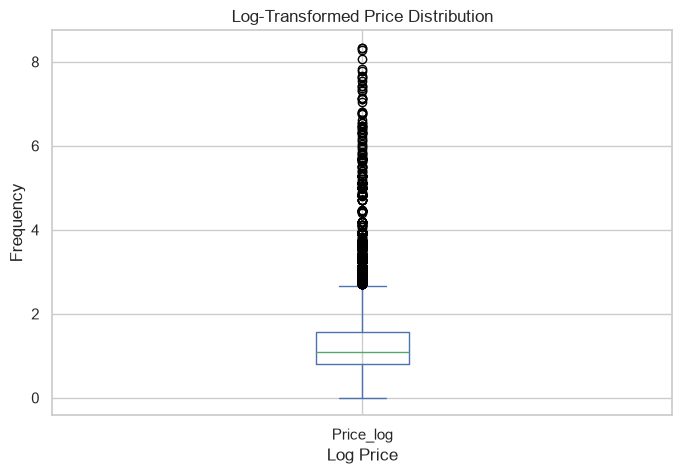

In [ ]:
# plotting boxplot of the log-transformed Price values to visualize the distribution.
df_clean['Price_log'].plot(kind='box', figsize=(8,5))
plt.title('Log-Transformed Price Distribution')
plt.xlabel('Log Price')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# RECALCULATING THE MEAN , MEDIAN , MIN , MAX 

df_clean['Price_log'].agg(['mean', 'median', 'min' , 'max']).round(2)

mean      1.16
median    1.08
min       0.00
max       8.33
Name: Price_log, dtype: float64

In [ ]:
# RECALCULATING THE SKEWNESS
df_clean['Price_log'].skew().round(2)

np.float64(0.93)

# UNIVARIATED ANALYSIS ON CATAGORICAL COLUMNS

### Price Column Analysis — Conclusion

1. The original Price distribution is extremely positively skewed, with a skewness of 145.69.
2. The mean price is 3.11, compared with a median of 1.95, indicating that high-priced items pull the mean upward.
3. The maximum recorded unit price is 4,161.06, demonstrating the presence of extremely high-priced observations.
4. Applying log1p() reduced the skewness from 145.69 to 0.93, substantially reducing the influence of extreme values on the distribution's shape.
5. The transformed Price column has a mean of approximately 1.16 and a median of approximately 1.08.

**Final observation:** Product prices are concentrated at the lower end of the distribution, with a small number of high-priced observations. The original Price column should be retained for business calculations, while the transformed column can be used for suitable statistical analysis.

In [ ]:

df_clean['Description'].describe()

count                                 392690
unique                                  3876
top       WHITE HANGING HEART T-LIGHT HOLDER
freq                                    2016
Name: Description, dtype: object

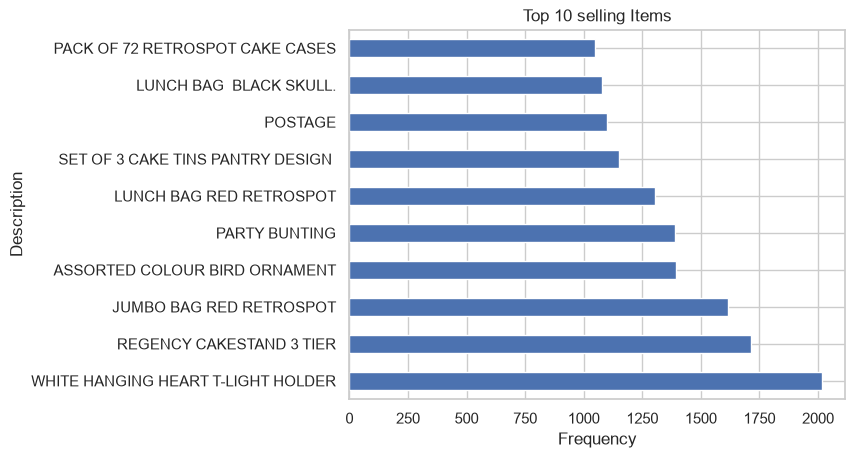

In [ ]:
# PLOTTING BAR GRAPH TO FIND TOP SELLING ITEMS 
df_clean['Description'].value_counts().head(10).plot(kind='barh')
plt.title('Top 10 selling Items')
plt.xlabel('Frequency')
plt.ylabel ('Description')
plt.show()

In [ ]:
df['Description'].isnull().sum()

np.int64(0)

### Country Column Analysis — Conclusion

1. The United Kingdom accounts for approximately 88% of the records in the displayed chart.
2. The remaining records are distributed across other countries, including Germany, France and several smaller markets.
3. The dataset is heavily concentrated in UK transactions, so the overall results are strongly influenced by the UK market.
4. These percentages represent transaction records, not each country's share of total sales revenue.

**Final observation:** The United Kingdom dominates the transaction records in this dataset. Country-level sales comparisons should be examined separately to understand the contribution of other markets.

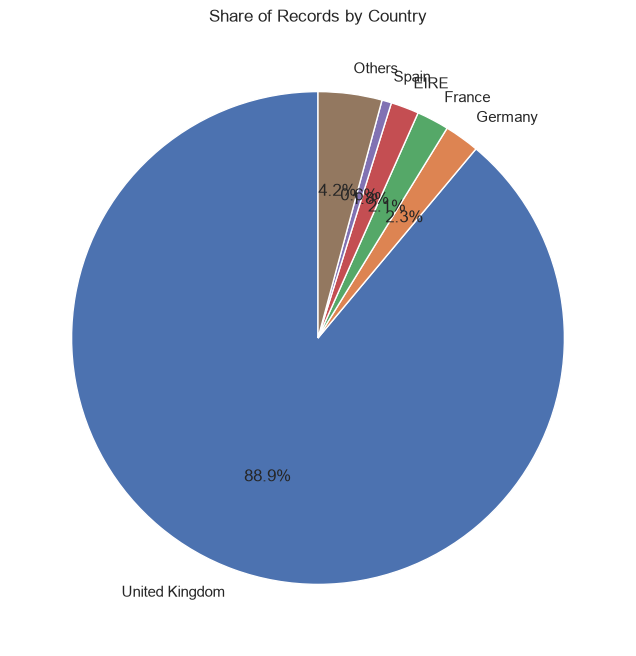

In [ ]:
# share of records by country (in %)
country_share = df_clean['Country'].value_counts(normalize=True) * 100

# keep top 5 countries and group the rest as Others
top5 = country_share.head(5)
top5['Others'] = country_share[5:].sum()

# pie chart
top5.plot(kind='pie', figsize=(8, 8), autopct='%1.1f%%', startangle=90)
plt.title('Share of Records by Country')
plt.ylabel('')
plt.show()

### StockCode Column Analysis — Conclusion

1. The bar chart displays the ten most frequently recorded stock codes.
2. StockCode 85123A has the highest frequency, at approximately 2,000 records.
3. Other stock codes also occur frequently, but their record counts are lower than that of 85123A.
4. Frequency alone does not establish which stock code contributes the most units sold or revenue.

**Final observation:** StockCode 85123A is the most frequently recorded stock code in the displayed chart. Its total quantity and revenue should be evaluated separately.

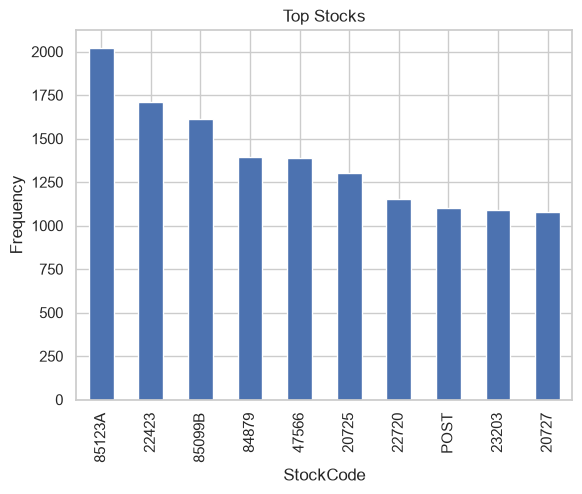

In [ ]:
df_clean['StockCode'].value_counts().head(10).plot(kind='bar')
plt.title('Top Stocks')
plt.xlabel('StockCode')
plt.ylabel ('Frequency')
plt.show()

In [ ]:
df_clean['StockCode'].isnull().sum()

np.int64(0)

### Invoice Date — Monthly Record Distribution Conclusion

1. The number of records increases substantially from September through November 2011.
2. November 2011 has the highest number of records, at approximately 63,000.
3. January through August generally show lower monthly record counts than September through November.
4. December 2011 has a lower count, but the dataset ends on 9 December 2011, making it an incomplete month.

**Final observation:** Transaction-record activity peaks in November 2011. Because December 2011 contains only partial data, it should not be directly compared with complete months.

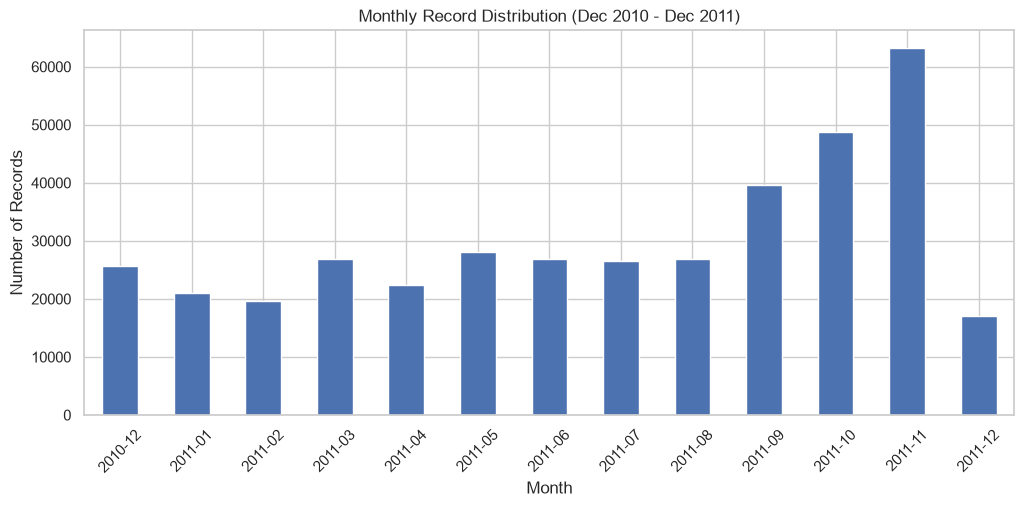

In [ ]:
df_clean['InvoiceDate'].dt.to_period('M').value_counts().sort_index().plot(kind='bar', figsize=(12, 5))
plt.title('Monthly Record Distribution (Dec 2010 - Dec 2011)')
plt.xlabel('Month')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df['InvoiceDate'].isnull().sum()

np.int64(0)

# BIVARIATED ANALYSIS 


# Numerical - Catagorical

### StockCode vs Quantity — Conclusion

1. The bar chart ranks the ten stock codes with the highest total quantities.
2. StockCode 84077 has the highest total quantity in the displayed chart, at approximately 54,000 units.
3. Several other stock codes also have high cumulative quantities, indicating that sales volume is concentrated among a subset of products.
4. The results measure total units, not transaction frequency or revenue.

**Final observation:** StockCode 84077 leads the displayed stock codes in total quantity sold. This does not necessarily mean it generates the highest revenue because unit prices differ across products.


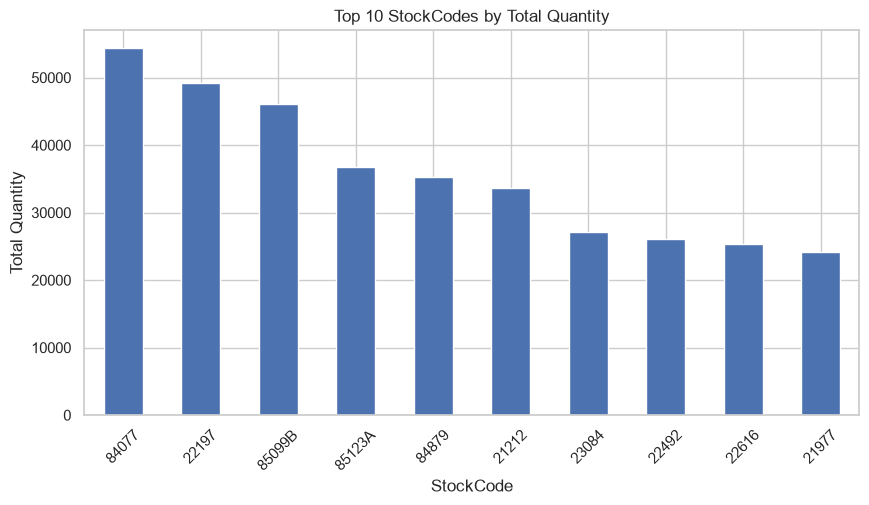

In [ ]:
df['top_stockcode']=df_clean.groupby('StockCode')['Quantity'].sum().sort_values(ascending=False).head(10).plot(kind='bar',figsize= (10,5))

plt.title('Top 10 StockCodes by Total Quantity')
plt.ylabel('Total Quantity')
plt.xticks(rotation=45)
plt.show()


# feature engineering by multiplying quantity and price to create a new column called Total_amount

In [ ]:
df_clean = df[(df['Price'] > 0) & (df['Price'] < 5000) &
              (df['Quantity'] > 0) & (df['Quantity'] < 10000)].copy()

df_clean['Total_Amount'] = df_clean['Price'] * df_clean['Quantity']

In [ ]:
df_clean['Total_Amount'].isnull().sum()

np.int64(0)

# # Country vs Total Amount — Conclusion

1. The United Kingdom has by far the highest total transaction amount in the displayed chart.
2. The Netherlands, EIRE, Germany and France appear among the next highest-contributing countries.
3. The difference between the United Kingdom and the other countries is substantial.
4. These results are based on Quantity × Price, summed across transactions, rather than transaction counts.

**Final observation:** The United Kingdom is the dominant market by total transaction amount in this dataset. However, because it also accounts for most records, further analysis of average transaction value or per-customer spending would help compare markets more fairly.


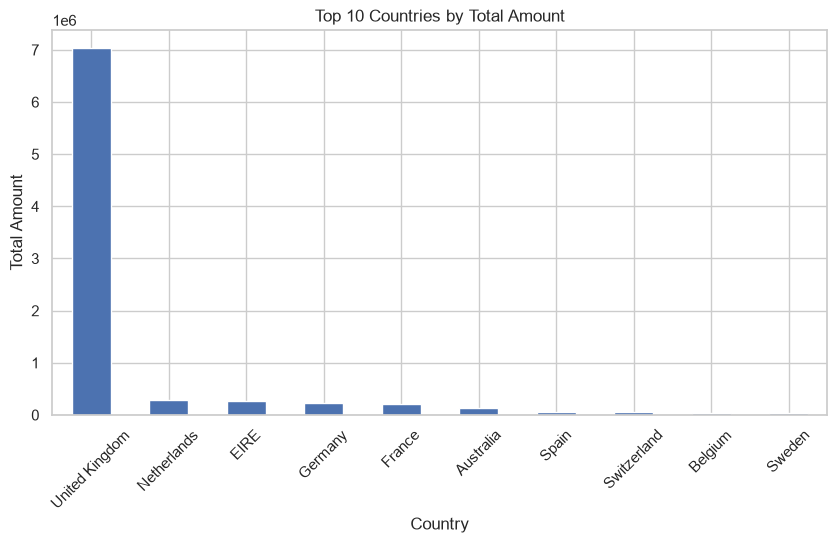

In [ ]:
df_clean.groupby('Country')['Total_Amount'].sum().sort_values(ascending=False).head(10).plot(kind='bar', figsize=(10,5))
plt.title('Top 10 Countries by Total Amount')
plt.xlabel('Country')
plt.ylabel('Total Amount')
plt.xticks(rotation=45)
plt.show()

# Description vs Total Amount — Conclusion

1. The bar chart ranks products by their total transaction amount.
2. REGENCY CAKESTAND 3 TIER has the highest total amount in the displayed chart, at approximately 140,000.
3. WHITE HANGING HEART T-LIGHT HOLDER also appears among the leading products by total amount.
4. The product with the highest transaction frequency is not necessarily the product with the highest total amount.

**Final observation:** REGENCY CAKESTAND 3 TIER leads the displayed products by total transaction amount, whereas WHITE HANGING HEART T-LIGHT HOLDER leads by record frequency. This demonstrates why frequency and monetary contribution should be analyzed separately.

<Axes: ylabel='Description'>

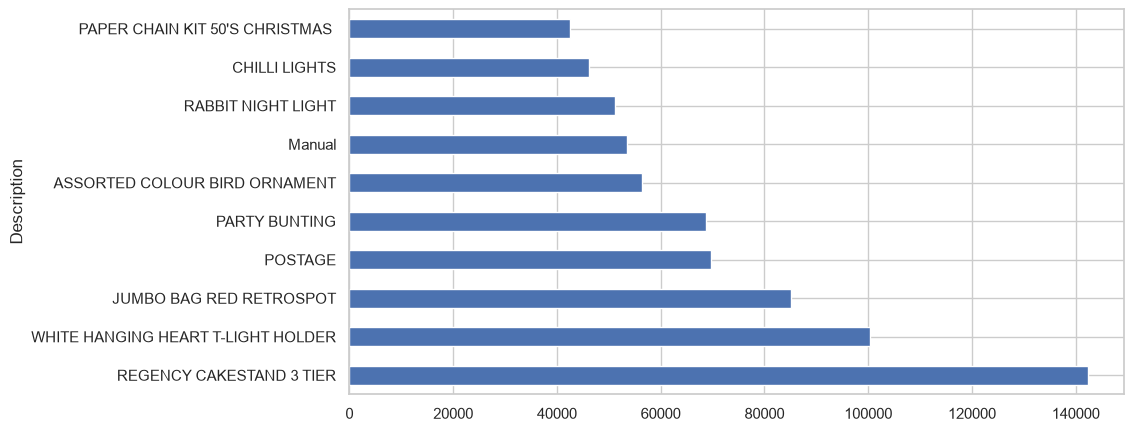

In [ ]:
df_clean.groupby('Description')['Total_Amount'].sum().sort_values(ascending=False).head(10).plot(kind='barh', figsize=(10,5))


# Numerical- Numerical


### Quantity vs Price — Conclusion

1. The scatter plot uses log-transformed Quantity and Price values.
2. Most observations are concentrated at relatively low unit prices, across a range of quantities.
3. High unit prices occur more frequently among lower-quantity transactions than among the largest-quantity transactions.
4. The plot does not show a strong positive relationship between unit price and quantity.
5. This visualization alone cannot establish causation or a statistically significant correlation.

**Final observation:** Unit price and transaction quantity do not exhibit a clear positive relationship in the displayed scatter plot. Large quantities do not necessarily correspond to high unit prices.

In [ ]:
df_clean.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'top_stockcode', 'Total_Amount'],
      dtype='str')

In [ ]:
df_clean['Quantity_log'] = np.log1p(df_clean['Quantity'])
df_clean['Price_log'] = np.log1p(df_clean['Price'])

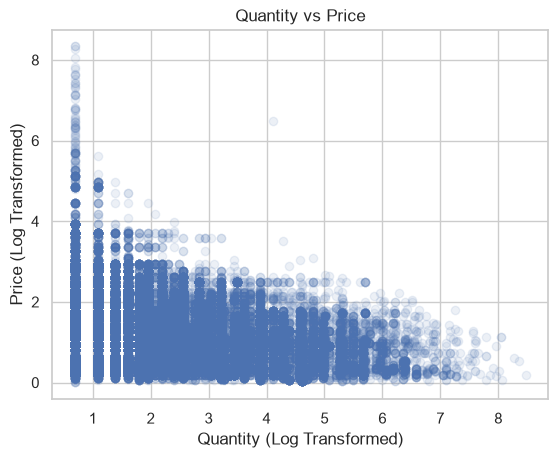

In [ ]:
plt.scatter (df_clean['Quantity_log'], df_clean['Price_log'], alpha=0.1)

plt.xlabel('Quantity (Log Transformed)')
plt.ylabel('Price (Log Transformed)')
plt.title('Quantity vs Price')
plt.show()

# Datetime vs Numerical Bivariate Analysis

### Invoice Date vs Total Amount — Monthly Sales Trend

1. Monthly total transaction amounts rise sharply from September 2011, with further increases in October and November.
2. November 2011 records the highest monthly total amount in the displayed chart.
3. The monthly amount fluctuates during the earlier months rather than increasing consistently.
4. December 2011 shows a sharp decline, but the dataset contains only transactions up to 9 December, so this decline should not be interpreted as a full-month sales drop.
5. The dataset covers approximately one year, which is insufficient to establish a recurring annual seasonal pattern.

**Final observation:** November 2011 is the strongest month by total transaction amount in the displayed analysis. The results suggest a late-year increase in sales activity, but additional years of data would be needed to confirm seasonality.

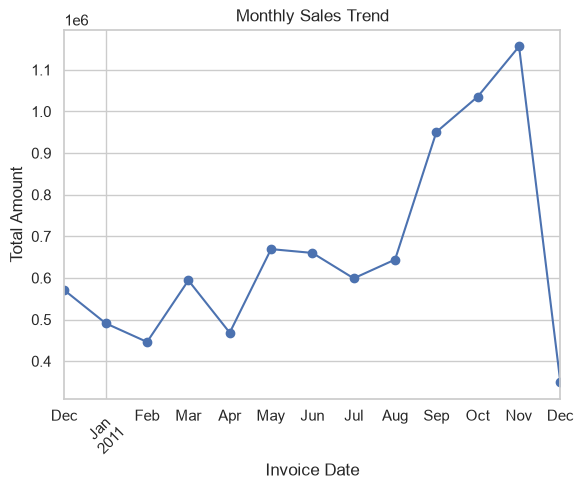

In [ ]:
df_clean.groupby(df_clean['InvoiceDate'].dt.to_period('M'))['Total_Amount'].sum().plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Invoice Date')
plt.ylabel('Total Amount')
plt.xticks(rotation=45)
plt.show()

# Catagorical - Catagorical


 ### Country vs Month — Conclusion

1. The United Kingdom has the highest number of transaction records across all displayed months, significantly exceeding every other country.
3. Transaction record counts vary across countries and months, indicating differences in recorded transaction activity.
4. All displayed countries have recorded transactions in every month shown in the heatmap.
5. The heatmap represents transaction record counts, not total quantities sold or revenue.

**Final Observation:** The United Kingdom dominates monthly transaction activity in the dataset. Belgium reaches 264 records in October, but this is much lower than the UK's monthly counts. These findings describe transaction frequency rather than sales revenue.

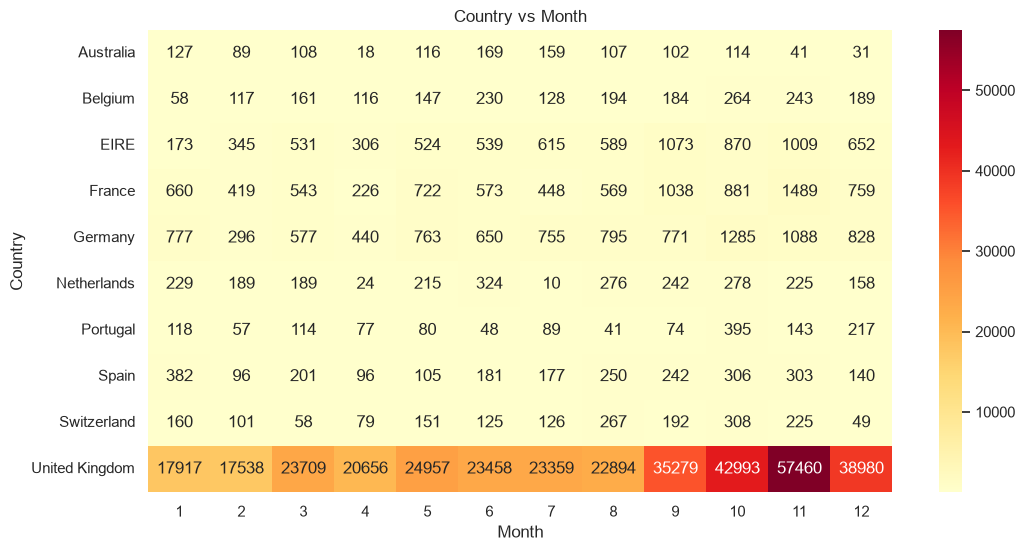

In [ ]:
# top 10 countries by number of records
top_countries = df_clean['Country'].value_counts().head(10).index

# filter data for these countries
df_top = df_clean[df_clean['Country'].isin(top_countries)]

# month column
df_top['Month'] = df_top['InvoiceDate'].dt.month

# country vs month table
table = pd.crosstab(df_top['Country'], df_top['Month'])

# plot
plt.figure(figsize=(12, 6))
sns.heatmap(table, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Country vs Month')
plt.xlabel('Month')
plt.ylabel('Country')
plt.show()